Visualização mensal dos perfis de consumo

Altera `MES` (e `ANO`, se quiseres) e corre as células. São mostradas 4 semanas (segunda a domingo, 28 dias) a começar na primeira segunda-feira do mês.

In [5]:
# ===== INPUT =====
MES = 1       # 1 a 12
ANO = 2008    # dados disponíveis de dez 2006 a nov 2010
# =================

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = pd.read_csv('dataset_consumo_simulado.csv', index_col='Datetime', parse_dates=True)

nomes = {
    'Perfil_1_Original': 'Original',
    'Perfil_2_Escritorio': 'Escritório',
    'Perfil_3_Familia': 'Família numerosa',
    'Perfil_4_Noturno': 'Trabalhador noturno',
    'Perfil_5_HomeOffice': 'Home office',
}
dias_pt = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
fmt_dia = lambda d: f'{dias_pt[d.dayofweek]} {d:%d/%m}'

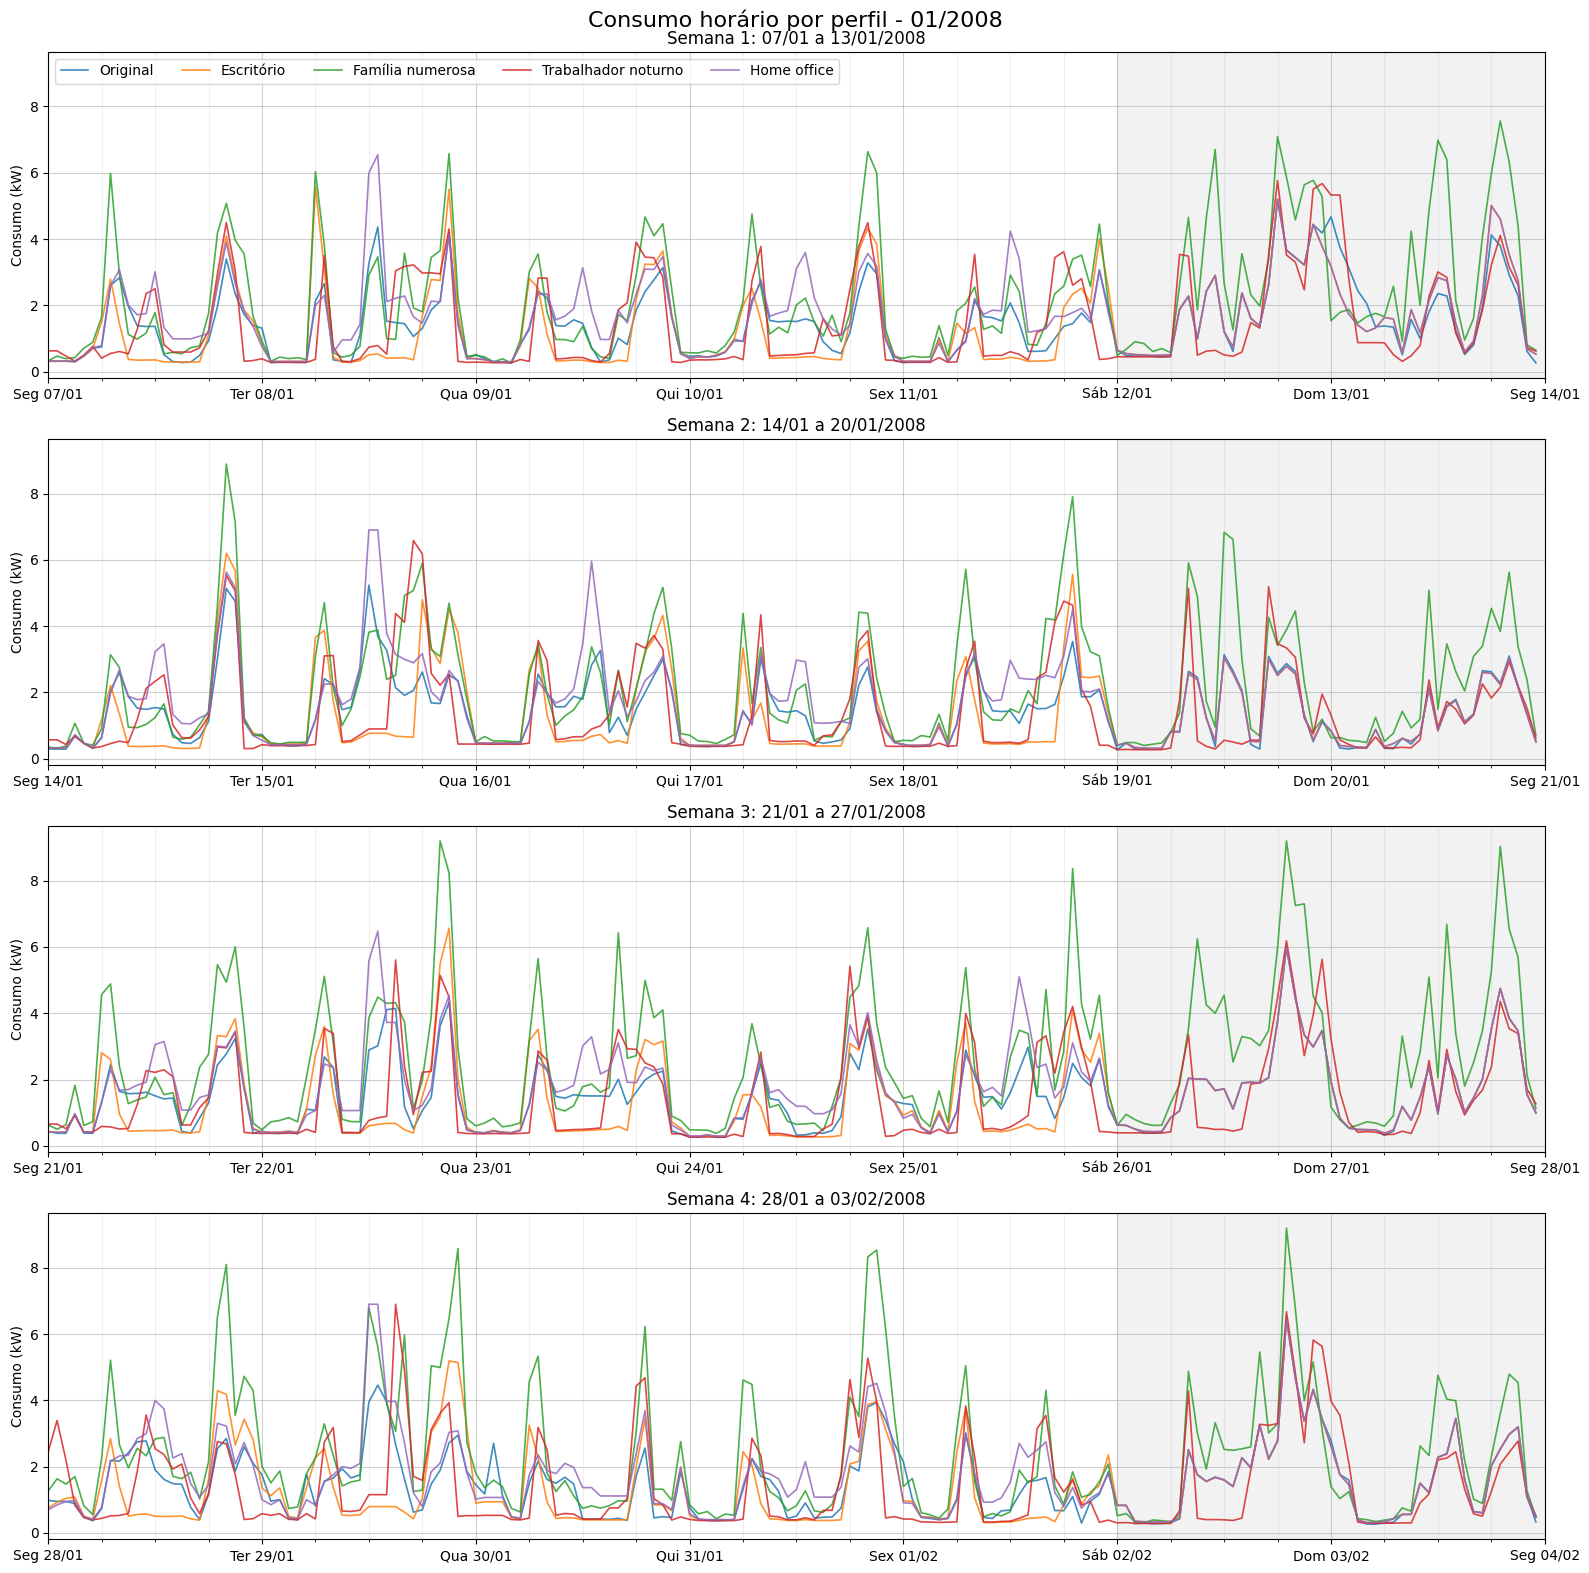

In [7]:
# Primeira segunda-feira do mês -> 4 semanas completas (28 dias)
inicio_mes = pd.Timestamp(year=ANO, month=MES, day=1)
inicio = inicio_mes + pd.Timedelta(days=(7 - inicio_mes.dayofweek) % 7)
fim = inicio + pd.Timedelta(days=28)
dados = df.loc[inicio:fim - pd.Timedelta(hours=1)]

if dados.empty:
    raise ValueError(f'Sem dados para {MES:02d}/{ANO}. Escolhe um mês entre 12/2006 e 11/2010.')

fig, axes = plt.subplots(4, 1, figsize=(16, 16), sharey=True)
for semana, ax in enumerate(axes):
    ini_sem = inicio + pd.Timedelta(days=7 * semana)
    fim_sem = ini_sem + pd.Timedelta(days=7)
    d = dados.loc[ini_sem:fim_sem - pd.Timedelta(hours=1)]
    for col in d.columns:
        ax.plot(d.index, d[col], label=nomes.get(col, col), linewidth=1.2, alpha=0.85)
    # Sombrear o fim de semana
    ax.axvspan(ini_sem + pd.Timedelta(days=5), fim_sem, color='grey', alpha=0.1)
    ax.set_xlim(ini_sem, fim_sem)
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: fmt_dia(pd.Timestamp(mdates.num2date(x)))))
    ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
    ax.grid(True, which='major', alpha=0.6)
    ax.grid(True, which='minor', alpha=0.2)
    ax.set_title(f'Semana {semana + 1}: {ini_sem:%d/%m} a {fim_sem - pd.Timedelta(days=1):%d/%m/%Y}')
    ax.set_ylabel('Consumo (kW)')

axes[0].legend(loc='upper left', ncol=5)
fig.suptitle(f'Consumo horário por perfil - {inicio_mes:%m/%Y}', fontsize=16)
plt.tight_layout()
plt.show()

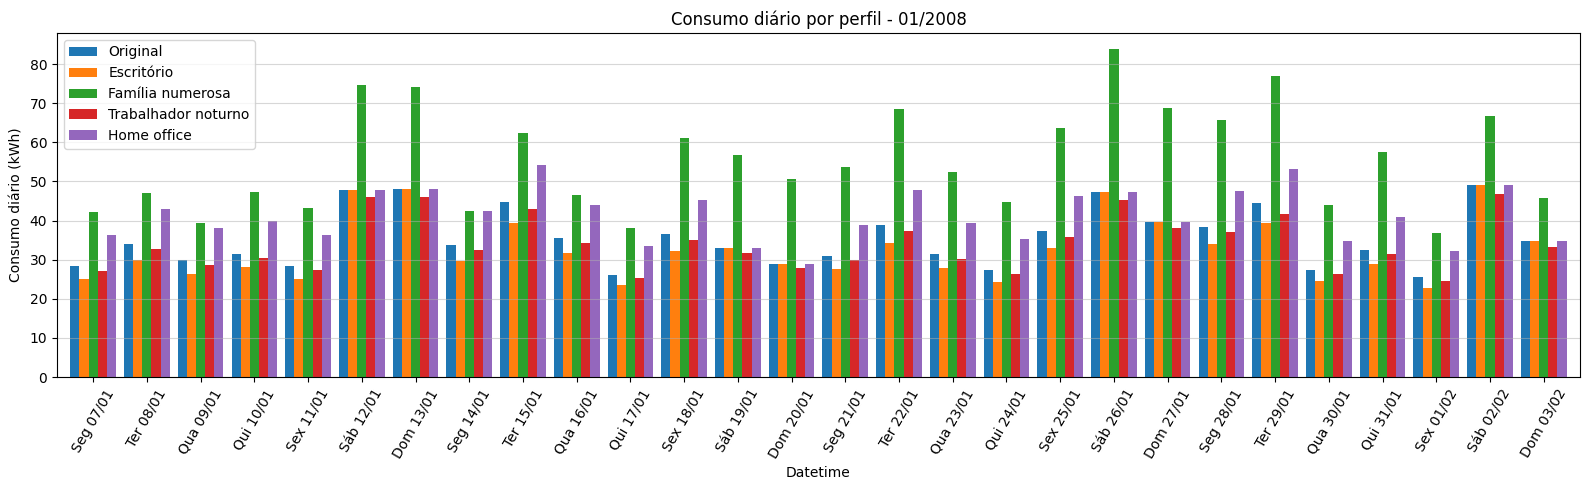

,Total 28 dias (kWh)
Original,992.0
Escritório,916.8
Família numerosa,1555.2
Trabalhador noturno,952.3
Home office,1158.2


In [8]:
# Consumo diário (kWh) por perfil nos 28 dias
diario = dados.resample('D').sum().rename(columns=nomes)
ax = diario.plot(kind='bar', figsize=(16, 5), width=0.85)
ax.set_xticklabels([fmt_dia(d) for d in diario.index], rotation=60)
ax.set_ylabel('Consumo diário (kWh)')
ax.set_title(f'Consumo diário por perfil - {inicio_mes:%m/%Y}')
ax.grid(True, axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

diario.sum().round(1).to_frame('Total 28 dias (kWh)')